# 07 — Results Visualization

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Generate all publication-quality figures for the Nexus manuscript  
**Output:** PDF + PNG figures (300 DPI) in `outputs/figures/`

---

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.visualization import (
    set_publication_style, save_figure, COLORS,
    plot_treatment_effects, plot_cate_heterogeneity
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"

set_publication_style()

In [2]:
# Load results
panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")

# Load method comparison if available
try:
    comparison = pd.read_csv(TABLE_DIR / "method_comparison.csv")
    print("Status: Method comparison loaded")
except:
    comparison = None
    print("Warning: Run Notebook 05 first to generate method comparison")

# Load CATEs if available
try:
    cate_df = pd.read_csv(PROCESSED_DIR / "cate_estimates.csv")
    print(f" CATEs loaded: {len(cate_df)} observations")
except:
    cate_df = None
    print("Warning: Run Notebook 05 first to generate CATEs")

Status: Method comparison loaded
 CATEs loaded: 2028 observations


---
## Figure 1: Policy Adoption Choropleth Map

In [3]:
import plotly.express as px

df_policies = pd.read_csv(PROJECT_ROOT / "data" / "interim" / "policies_cleaned.csv")

# Count policies per country
policy_count = df_policies.groupby("iso3").size().reset_index(name="n_policies")

fig_map = px.choropleth(
    policy_count,
    locations="iso3",
    color="n_policies",
    color_continuous_scale="Blues",
    title="Figure 1: Climate Policy Coverage by Country",
    labels={"n_policies": "Number of Policies"},
)
fig_map.update_layout(width=1000, height=500, margin=dict(t=50, b=0, l=0, r=0))
fig_map.show()

---
## Figure 2: Treatment Effects Forest Plot

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig2_treatment_effects.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig2_treatment_effects.pdf


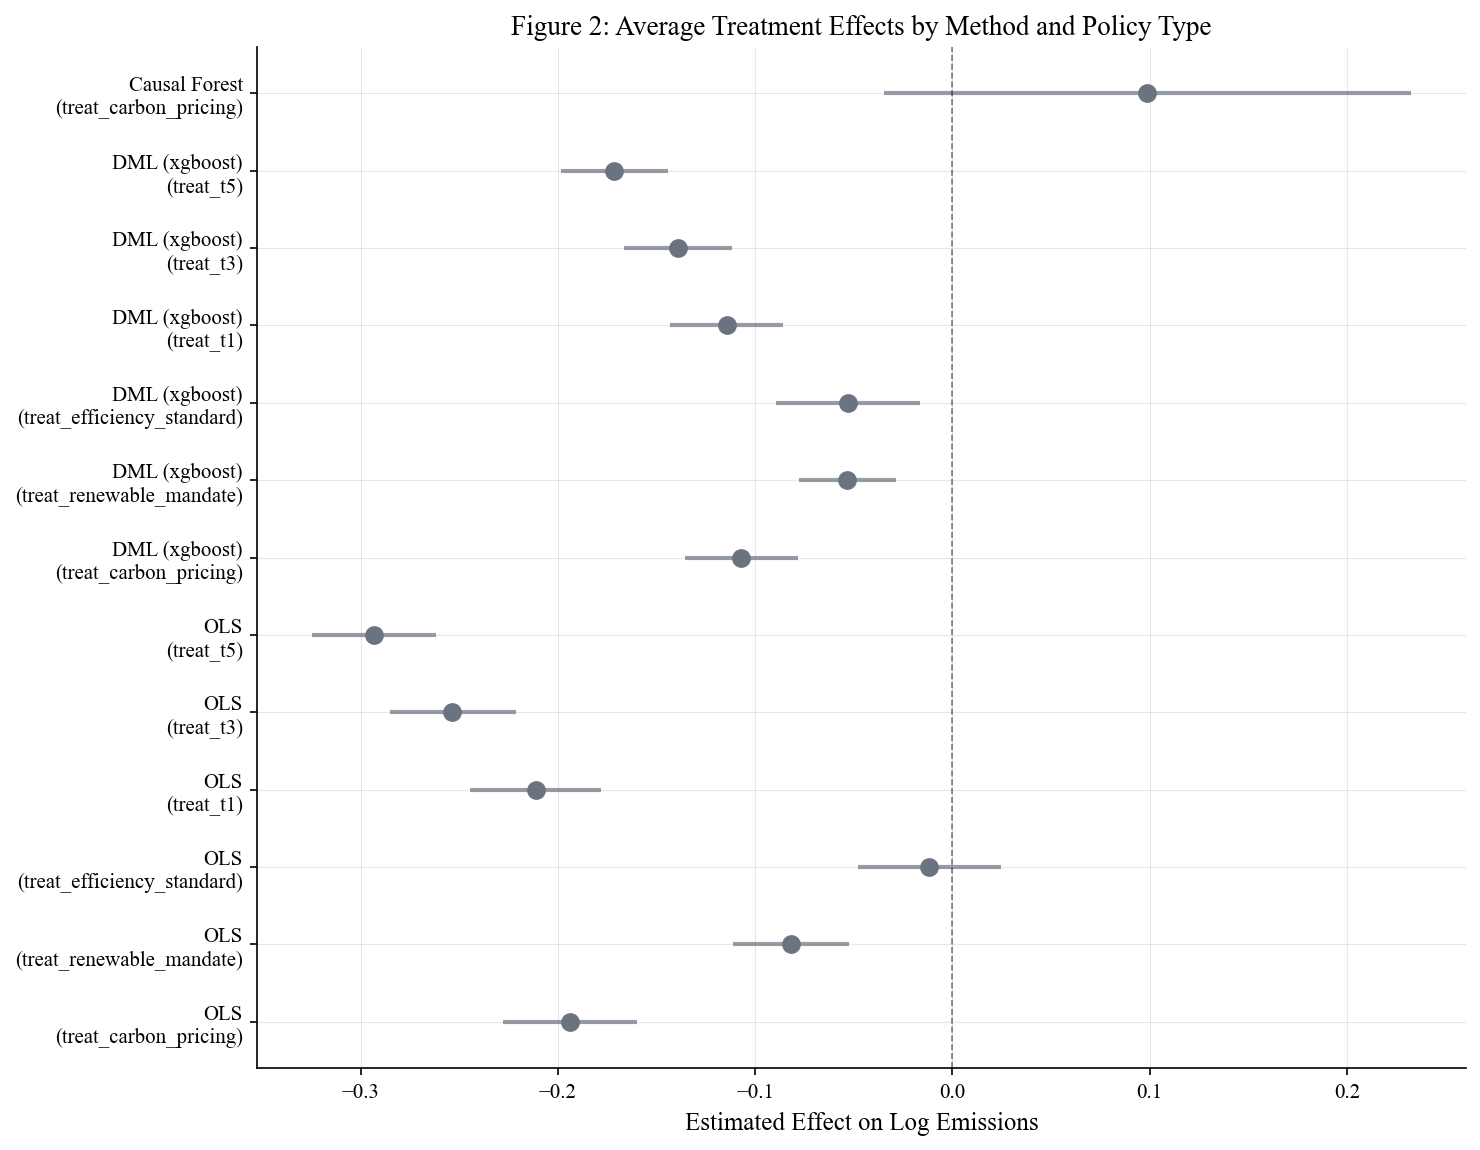

In [4]:
if comparison is not None:
    # Parse comparison table for plotting
    effects_data = []
    for _, row in comparison.iterrows():
        ci = row.get("95% CI", "[0, 0]")
        try:
            ci_vals = ci.strip("[]").split(",")
            effects_data.append({
                "policy_type": f"{row['Method']}\n({row['Treatment']})",
                "estimate": float(row["Estimate"]),
                "ci_lower": float(ci_vals[0]),
                "ci_upper": float(ci_vals[1]),
            })
        except:
            pass
    
    if effects_data:
        effects_df = pd.DataFrame(effects_data)
        fig = plot_treatment_effects(
            effects_df,
            title="Figure 2: Average Treatment Effects by Method and Policy Type",
            figsize=(10, max(4, len(effects_df) * 0.6)),
        )
        save_figure(fig, "fig2_treatment_effects")
        plt.show()
else:
    print("Warning: No comparison data — run Notebook 05 first")

---
## Figure 3–4: CATE Heterogeneity

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig3_cate_gdp.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig3_cate_gdp.pdf


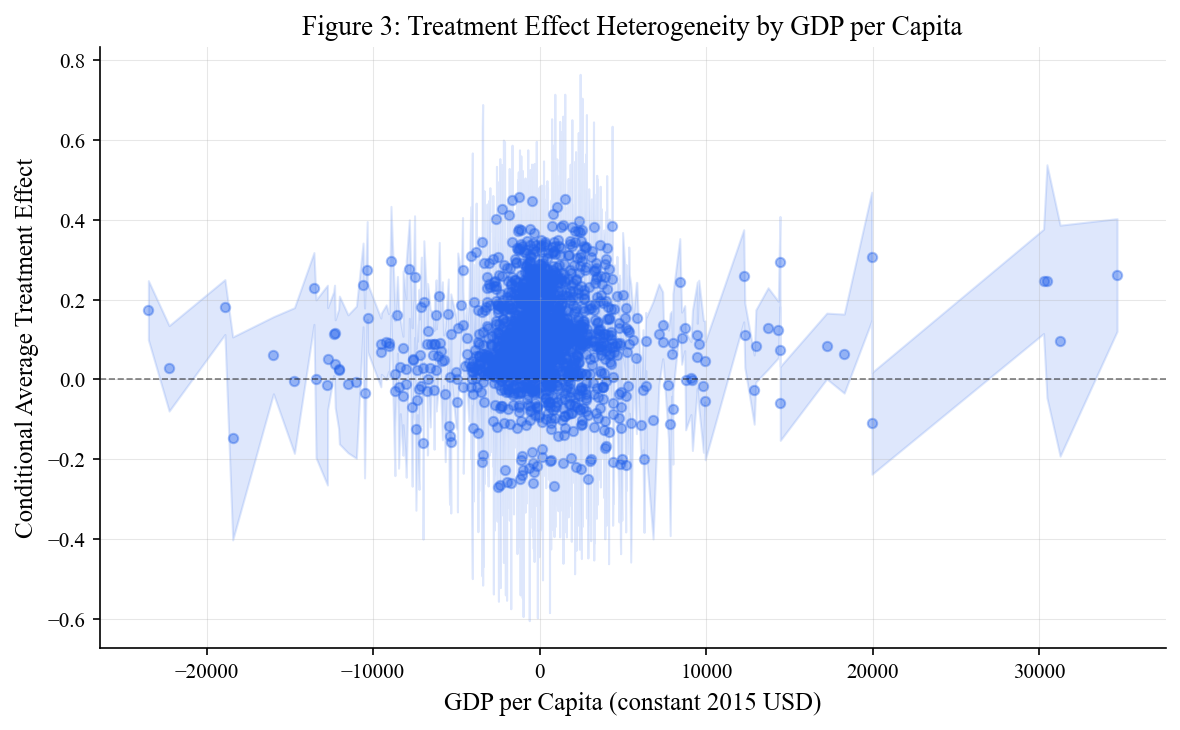

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig4_cate_governance.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig4_cate_governance.pdf


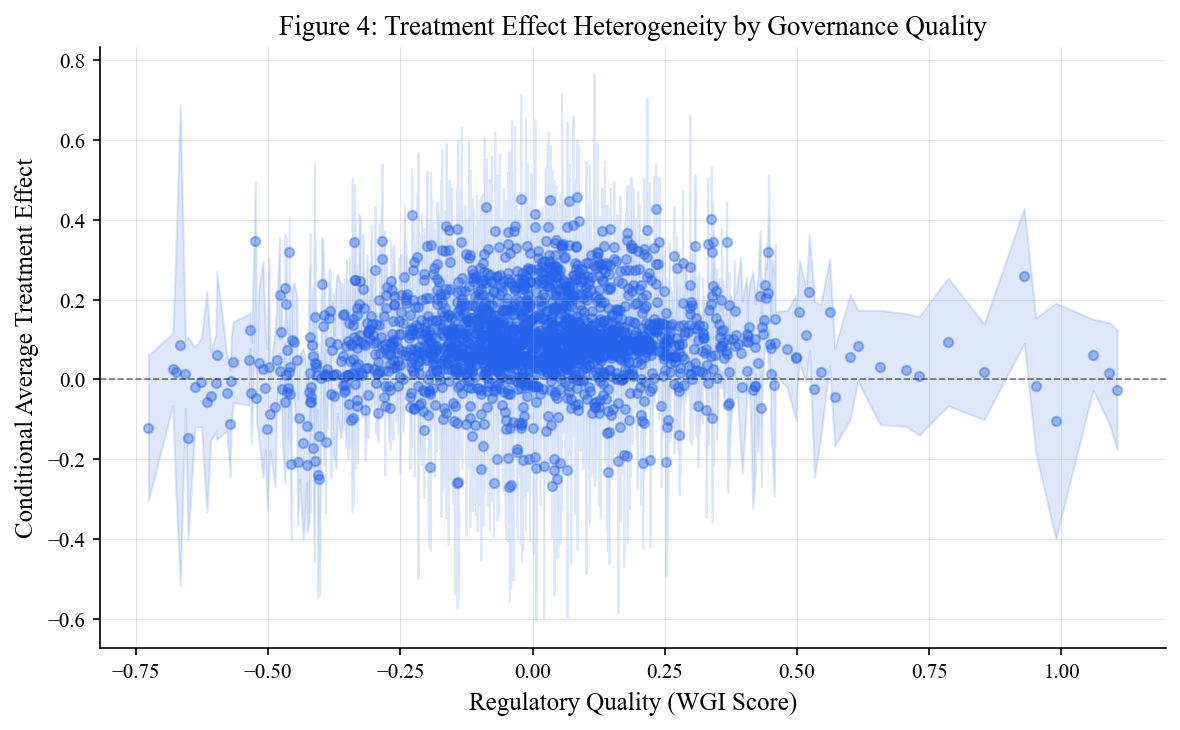

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig5_cate_distribution.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig5_cate_distribution.pdf


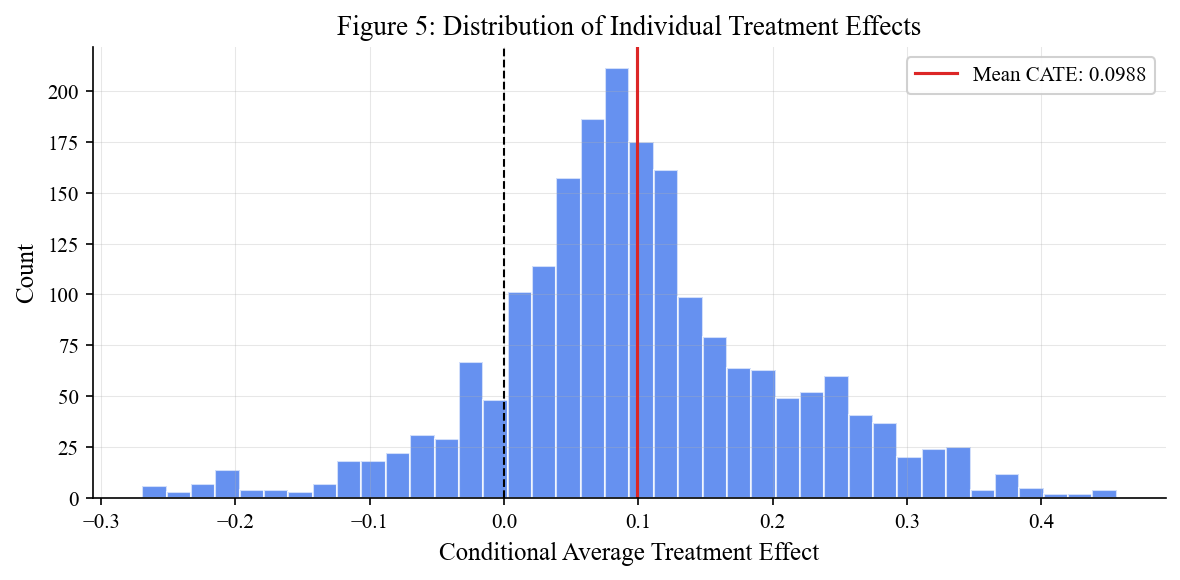

In [5]:
if cate_df is not None:
    # CATE vs GDP per capita
    if "gdp_per_capita" in cate_df.columns:
        fig = plot_cate_heterogeneity(
            cate_df, "gdp_per_capita", "GDP per Capita (constant 2015 USD)",
            title="Figure 3: Treatment Effect Heterogeneity by GDP per Capita"
        )
        save_figure(fig, "fig3_cate_gdp")
        plt.show()

    # CATE vs Governance
    if "regulatory_quality" in cate_df.columns:
        fig = plot_cate_heterogeneity(
            cate_df, "regulatory_quality", "Regulatory Quality (WGI Score)",
            title="Figure 4: Treatment Effect Heterogeneity by Governance Quality"
        )
        save_figure(fig, "fig4_cate_governance")
        plt.show()

    # CATE distribution
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(cate_df["cate"], bins=40, color=COLORS["primary"], alpha=0.7, edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(cate_df["cate"].mean(), color=COLORS["danger"], linestyle="-", linewidth=1.5,
               label=f"Mean CATE: {cate_df['cate'].mean():.4f}")
    ax.set_xlabel("Conditional Average Treatment Effect")
    ax.set_ylabel("Count")
    ax.set_title("Figure 5: Distribution of Individual Treatment Effects")
    ax.legend()
    plt.tight_layout()
    save_figure(fig, "fig5_cate_distribution")
    plt.show()
else:
    print("Warning: No CATE data — run Notebook 05 first")

In [6]:
print("\nSuccess: All publication figures generated")
print(f"Output Directory: Figures saved to: {FIG_DIR}")
print("Next Step: Proceed to Notebook 08: Paper Tables")


Success: All publication figures generated
Output Directory: Figures saved to: f:\Nexus_Projects\causal-climate-policy\outputs\figures
Next Step: Proceed to Notebook 08: Paper Tables
